In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path = 'results/mcts_pi_svgp_cs_Sepang_10_lw1.5/traj_config_mcts_known_dyn_action_prior_cpp_t1_s42_Sepang_10_20260227_103938.csv'
df = pd.read_csv(csv_path, comment='#')
df = df[:1474]
x = df['S_x'].values
y = df['S_y'].values
kappa = df['max_kappa'].values
v_actual = df['S_vel'].values

# v_max = min(12, sqrt(a_lat_budget / kappa))
a_lat_budget = 12.5868
v_max_raw = np.sqrt(a_lat_budget / np.maximum(np.abs(kappa), 1e-6))
v_max = np.minimum(v_max_raw, 12.0)

print(f'v_max  stats: min={v_max.min():.2f}, max={v_max.max():.2f}, mean={v_max.mean():.2f}')
print(f'v_actual stats: min={v_actual.min():.2f}, max={v_actual.max():.2f}, mean={v_actual.mean():.2f}')
print(f'Points where v_actual > v_max: {(v_actual > v_max).sum()} / {len(v_max)}')

v_max  stats: min=3.79, max=12.00, mean=8.44
v_actual stats: min=0.00, max=12.20, mean=8.07
Points where v_actual > v_max: 503 / 1474


In [29]:
min(v_actual)

0.0

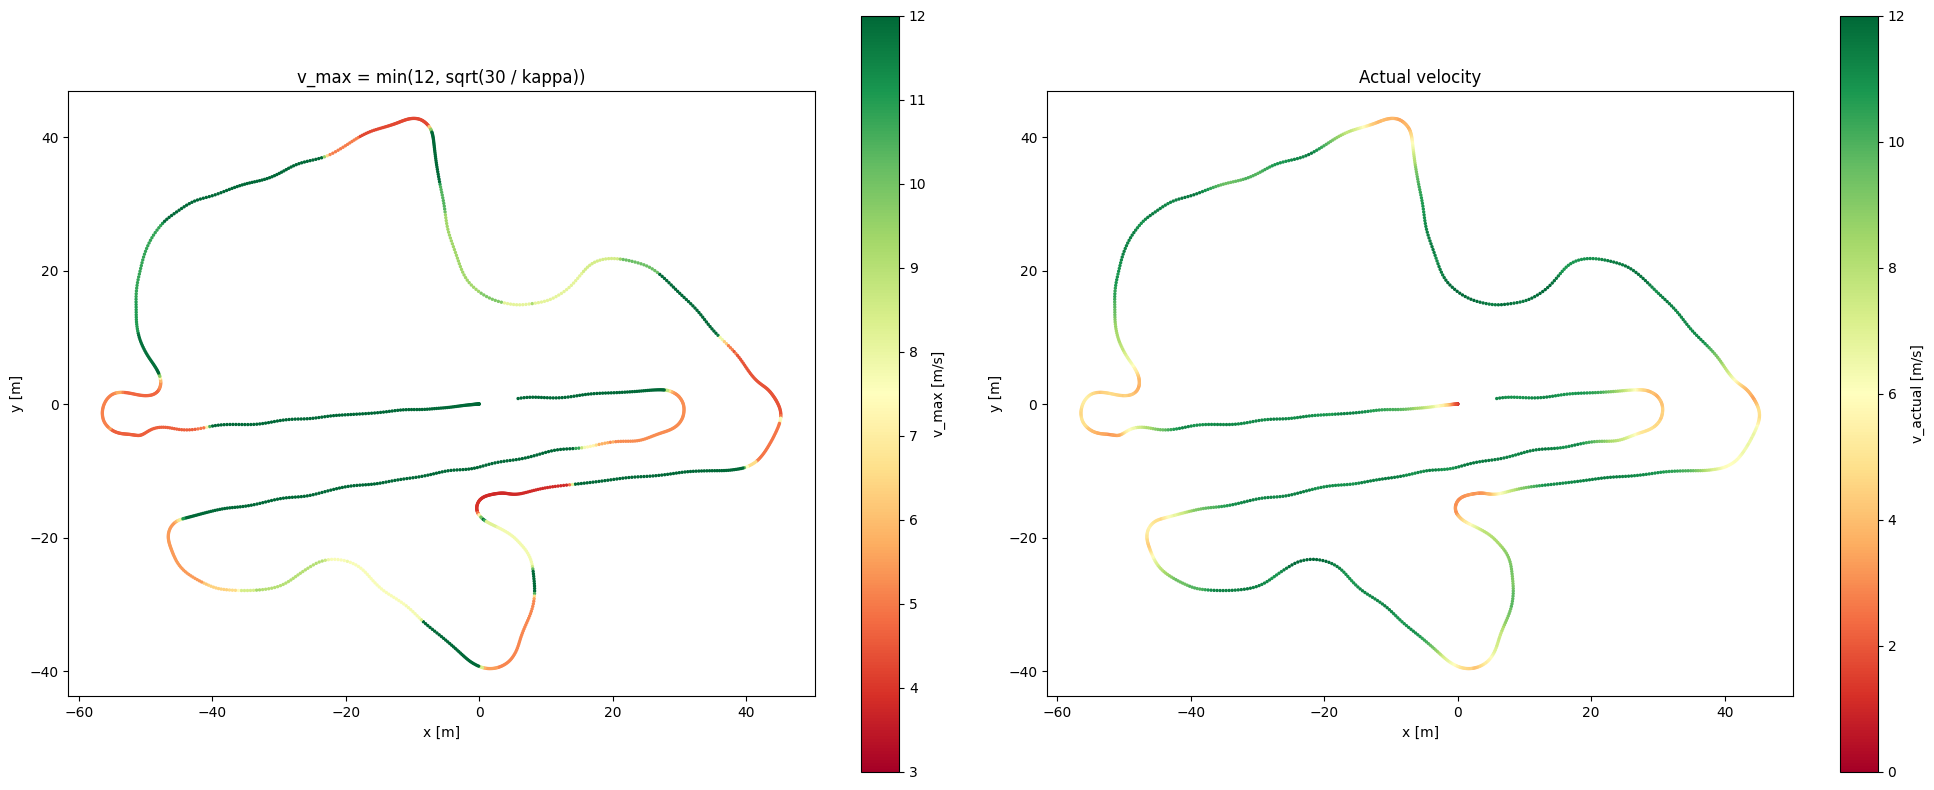

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Left: trajectory colored by v_max
sc1 = axes[0].scatter(x, y, c=v_max, cmap='RdYlGn', s=2, vmin=3, vmax=12)
axes[0].set_title('v_max = min(12, sqrt(30 / kappa))')
axes[0].set_xlabel('x [m]')
axes[0].set_ylabel('y [m]')
axes[0].set_aspect('equal')
plt.colorbar(sc1, ax=axes[0], label='v_max [m/s]')

# Right: trajectory colored by actual velocity
sc2 = axes[1].scatter(x, y, c=v_actual, cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[1].set_title('Actual velocity')
axes[1].set_xlabel('x [m]')
axes[1].set_ylabel('y [m]')
axes[1].set_aspect('equal')
plt.colorbar(sc2, ax=axes[1], label='v_actual [m/s]')

plt.tight_layout()
plt.show()

In [31]:
# Load Steven Gong's optimized raceline for Sepang (mu=1.0489)
sg_path = 'maps/Sepang_10489/traj_race_cl_Sepang_10489_map.csv'
sg = pd.read_csv(sg_path, comment='#', sep=';\\s*', engine='python',
                 names=['s_m', 'x_m', 'y_m', 'psi_rad', 'kappa_radpm', 'vx_mps', 'ax_mps2'])

sg_x = sg['x_m'].values
sg_y = sg['y_m'].values
sg_v = sg['vx_mps'].values
sg_kappa = sg['kappa_radpm'].values

print(f'Steven Gong raceline: {len(sg)} points')
print(f'  v_opt stats: min={sg_v.min():.2f}, max={sg_v.max():.2f}, mean={sg_v.mean():.2f}')
print(f'  kappa stats: min={sg_kappa.min():.4f}, max={sg_kappa.max():.4f}')

Steven Gong raceline: 2417 points
  v_opt stats: min=3.34, max=12.00, mean=10.94
  kappa stats: min=-0.5061, max=0.8029


In [32]:
# Load centerline and compute curvature (same formula as Track._compute_curvature)
cl_path = 'maps/Sepang_10489/Sepang_centerline.csv'
cl = pd.read_csv(cl_path, comment='#', skipinitialspace=True,
                 names=['x_m', 'y_m', 'w_tr_right', 'w_tr_left'])

cl_x = cl['x_m'].values
cl_y = cl['y_m'].values

# Compute arc length
diffs = np.diff(np.column_stack([cl_x, cl_y]), axis=0)
seg_lengths = np.linalg.norm(diffs, axis=1)
cl_s = np.concatenate([[0.0], np.cumsum(seg_lengths)])
ds_cl = np.median(np.diff(cl_s))

# Compute curvature: kappa = |x'*y'' - y'*x''| / (x'^2 + y'^2)^(3/2)
# Central differences with wrapping (closed track)
dx = np.gradient(cl_x, cl_s)
dy = np.gradient(cl_y, cl_s)
ddx = np.gradient(dx, cl_s)
ddy = np.gradient(dy, cl_s)
cl_kappa = np.abs(dx * ddy - dy * ddx) / (dx**2 + dy**2)**1.5

print(f"Centerline: {len(cl)} points, ds = {ds_cl:.4f} m")
print(f"  kappa stats: min={cl_kappa.min():.4f}, max={cl_kappa.max():.4f}, mean={cl_kappa.mean():.4f}")

# Forward-backward velocity profile on CENTERLINE
a_lat_budget = 12.0
a_max = 9.51
v_cap = 12.0
N_cl = len(cl_kappa)

# Step 1: per-point curvature speed limit
v_limit_cl = np.minimum(v_cap, np.sqrt(a_lat_budget / np.maximum(cl_kappa, 1e-6)))

# Step 2: backward pass
v_bwd_cl = v_limit_cl.copy()
for i in range(N_cl - 2, -1, -1):
    v_bwd_cl[i] = min(v_bwd_cl[i], np.sqrt(v_bwd_cl[i + 1] ** 2 + 2 * a_max * ds_cl))

# Step 3: forward pass
v_fwd_cl = v_bwd_cl.copy()
for i in range(1, N_cl):
    v_fwd_cl[i] = min(v_fwd_cl[i], np.sqrt(v_fwd_cl[i - 1] ** 2 + 2 * a_max * ds_cl))

v_optimal_cl = v_fwd_cl

print(f"\nv_limit (curvature only): min={v_limit_cl.min():.2f}, max={v_limit_cl.max():.2f}, mean={v_limit_cl.mean():.2f}")
print(f"v_optimal (fwd-bwd):      min={v_optimal_cl.min():.2f}, max={v_optimal_cl.max():.2f}, mean={v_optimal_cl.mean():.2f}")
print(f"Steven Gong (raceline):   min={sg_v.min():.2f}, max={sg_v.max():.2f}, mean={sg_v.mean():.2f}")

Centerline: 1108 points, ds = 0.4399 m
  kappa stats: min=0.0000, max=0.8379, mean=0.0630

v_limit (curvature only): min=3.78, max=12.00, mean=11.16
v_optimal (fwd-bwd):      min=3.78, max=12.00, mean=10.62
Steven Gong (raceline):   min=3.34, max=12.00, mean=10.94


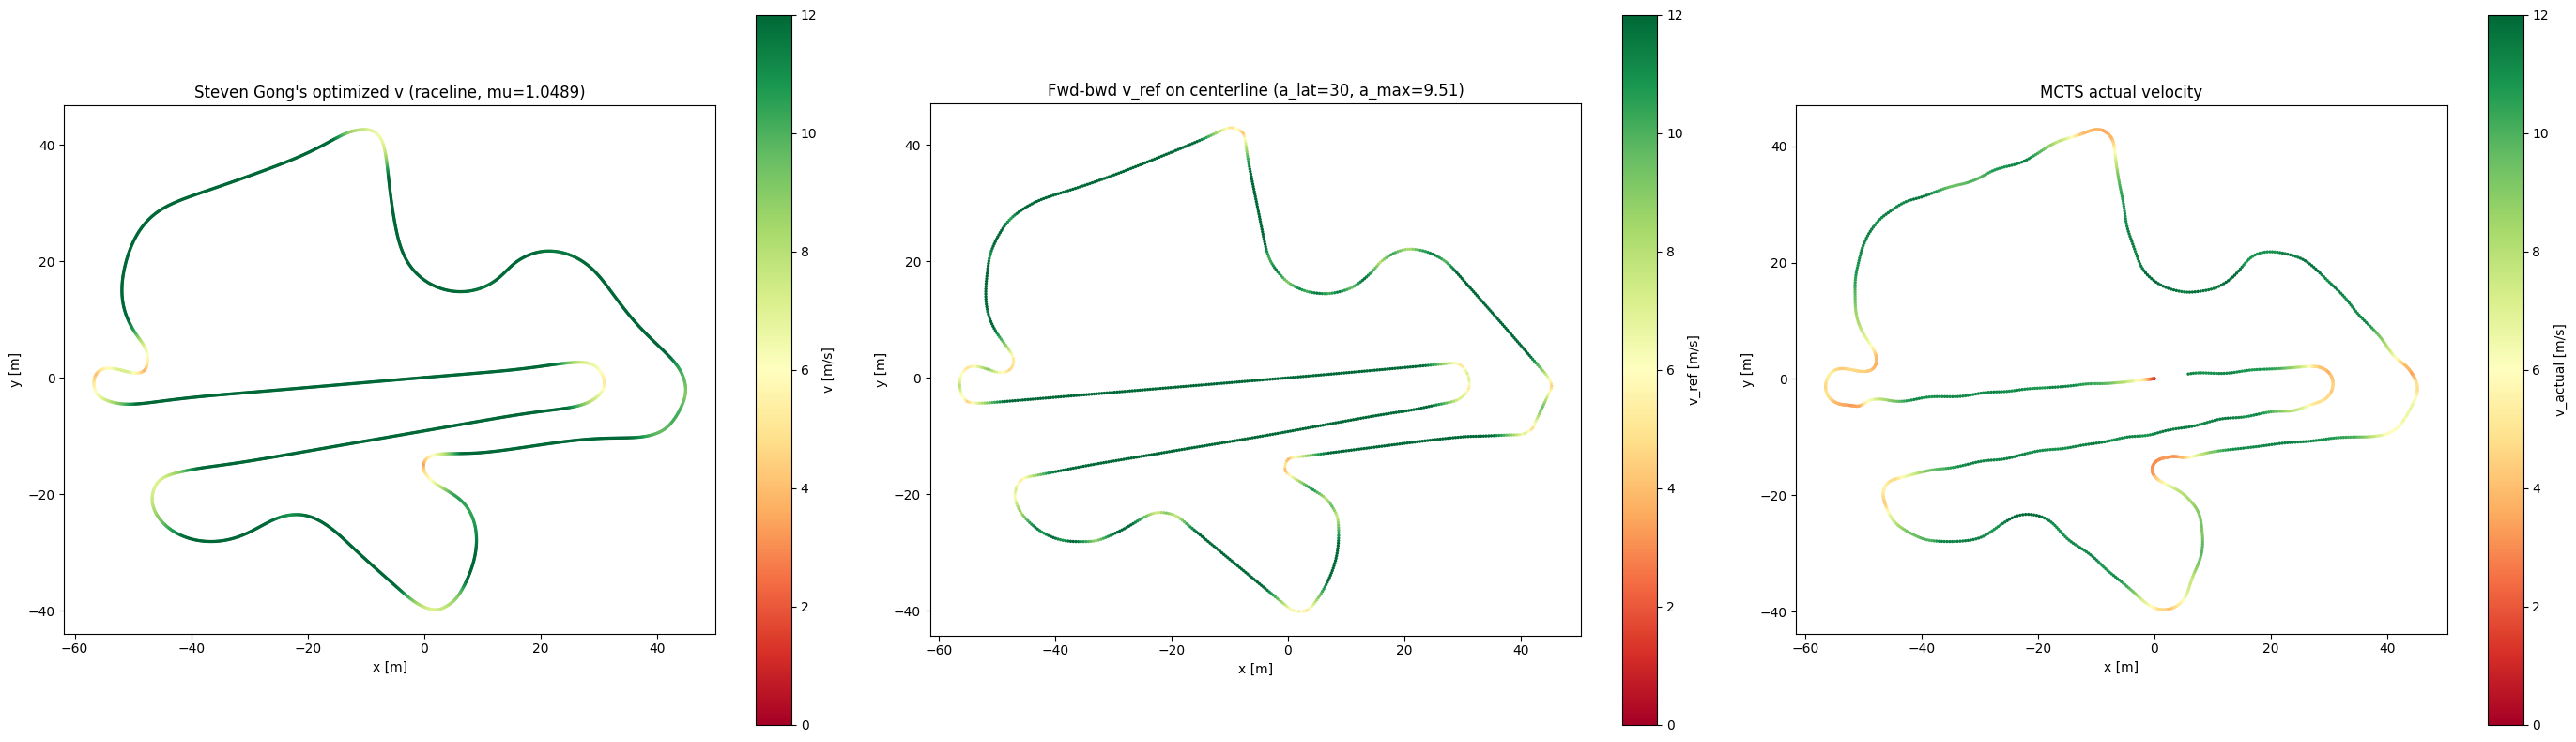

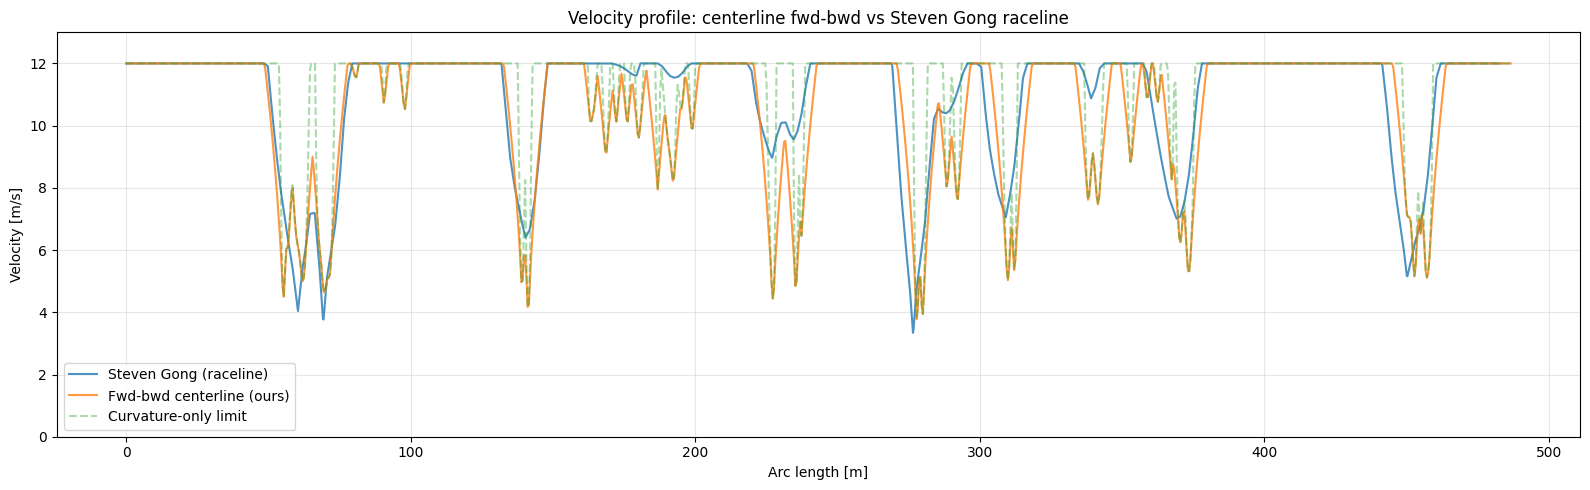

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(28, 8))

# Left: Steven Gong's optimized velocity (raceline)
sc0 = axes[0].scatter(sg_x, sg_y, c=sg_v, cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[0].set_title("Steven Gong's optimized v (raceline, mu=1.0489)")
axes[0].set_xlabel('x [m]')
axes[0].set_ylabel('y [m]')
axes[0].set_aspect('equal')
plt.colorbar(sc0, ax=axes[0], label='v [m/s]')

# Middle: our forward-backward on CENTERLINE
sc1 = axes[1].scatter(cl_x, cl_y, c=v_optimal_cl, cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[1].set_title('Fwd-bwd v_ref on centerline (a_lat=30, a_max=9.51)')
axes[1].set_xlabel('x [m]')
axes[1].set_ylabel('y [m]')
axes[1].set_aspect('equal')
plt.colorbar(sc1, ax=axes[1], label='v_ref [m/s]')

# Right: MCTS actual velocity
sc2 = axes[2].scatter(x, y, c=v_actual, cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[2].set_title('MCTS actual velocity')
axes[2].set_xlabel('x [m]')
axes[2].set_ylabel('y [m]')
axes[2].set_aspect('equal')
plt.colorbar(sc2, ax=axes[2], label='v_actual [m/s]')

plt.tight_layout()
plt.show()

# Velocity vs arc length — overlay centerline fwd-bwd with Steven Gong
fig2, ax2 = plt.subplots(figsize=(16, 5))
ax2.plot(sg['s_m'], sg_v, label="Steven Gong (raceline)", alpha=0.8)
ax2.plot(cl_s, v_optimal_cl, label="Fwd-bwd centerline (ours)", alpha=0.8)
ax2.plot(cl_s, v_limit_cl, label="Curvature-only limit", alpha=0.4, linestyle='--')
ax2.set_xlabel('Arc length [m]')
ax2.set_ylabel('Velocity [m/s]')
ax2.set_title('Velocity profile: centerline fwd-bwd vs Steven Gong raceline')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 13)
plt.tight_layout()
plt.show()

In [ ]:
# ===== YasMarina =====
# Load MCTS trajectory
ym_traj_path = 'results/mcts_pi_svgp_cs_YasMarina_10_lw1.5/traj_config_mcts_known_dyn_action_prior_cpp_t1_s42_YasMarina_10_20260226_194728.csv'
ym_df = pd.read_csv(ym_traj_path, comment='#')
ym_x_mcts = ym_df['S_x'].values
ym_y_mcts = ym_df['S_y'].values
ym_v_actual = ym_df['S_vel'].values

# Load Steven Gong's raceline
ym_sg_path = 'maps/YasMarina_10489/traj_race_cl_YasMarina_10489_map.csv'
ym_sg = pd.read_csv(ym_sg_path, comment='#', sep=';\\s*', engine='python',
                     names=['s_m', 'x_m', 'y_m', 'psi_rad', 'kappa_radpm', 'vx_mps', 'ax_mps2'])

# Load centerline and compute curvature
ym_cl_path = 'maps/YasMarina_10489/YasMarina_centerline.csv'
ym_cl = pd.read_csv(ym_cl_path, comment='#', skipinitialspace=True,
                     names=['x_m', 'y_m', 'w_tr_right', 'w_tr_left'])

ym_cl_x = ym_cl['x_m'].values
ym_cl_y = ym_cl['y_m'].values

diffs = np.diff(np.column_stack([ym_cl_x, ym_cl_y]), axis=0)
seg_lengths = np.linalg.norm(diffs, axis=1)
ym_cl_s = np.concatenate([[0.0], np.cumsum(seg_lengths)])
ym_ds = np.median(np.diff(ym_cl_s))

dx = np.gradient(ym_cl_x, ym_cl_s)
dy = np.gradient(ym_cl_y, ym_cl_s)
ddx = np.gradient(dx, ym_cl_s)
ddy = np.gradient(dy, ym_cl_s)
ym_cl_kappa = np.abs(dx * ddy - dy * ddx) / (dx**2 + dy**2)**1.5

# Forward-backward on centerline
a_lat_budget = 20.0
a_max = 9.51
v_cap = 12.0
N_ym = len(ym_cl_kappa)

v_limit_ym = np.minimum(v_cap, np.sqrt(a_lat_budget / np.maximum(ym_cl_kappa, 1e-6)))

v_bwd_ym = v_limit_ym.copy()
for i in range(N_ym - 2, -1, -1):
    v_bwd_ym[i] = min(v_bwd_ym[i], np.sqrt(v_bwd_ym[i + 1] ** 2 + 2 * a_max * ym_ds))

v_fwd_ym = v_bwd_ym.copy()
for i in range(1, N_ym):
    v_fwd_ym[i] = min(v_fwd_ym[i], np.sqrt(v_fwd_ym[i - 1] ** 2 + 2 * a_max * ym_ds))

v_optimal_ym = v_fwd_ym

print(f"YasMarina centerline: {N_ym} points, ds = {ym_ds:.4f} m")
print(f"v_optimal (fwd-bwd):    min={v_optimal_ym.min():.2f}, max={v_optimal_ym.max():.2f}, mean={v_optimal_ym.mean():.2f}")
print(f"Steven Gong (raceline): min={ym_sg['vx_mps'].min():.2f}, max={ym_sg['vx_mps'].max():.2f}, mean={ym_sg['vx_mps'].mean():.2f}")
print(f"MCTS actual:            min={ym_v_actual.min():.2f}, max={ym_v_actual.max():.2f}, mean={ym_v_actual.mean():.2f}")

YasMarina centerline: 1110 points, ds = 0.3589 m
v_optimal (fwd-bwd):    min=4.06, max=12.00, mean=10.60
Steven Gong (raceline): min=2.17, max=12.00, mean=10.44
MCTS actual:            min=0.00, max=11.66, mean=6.53


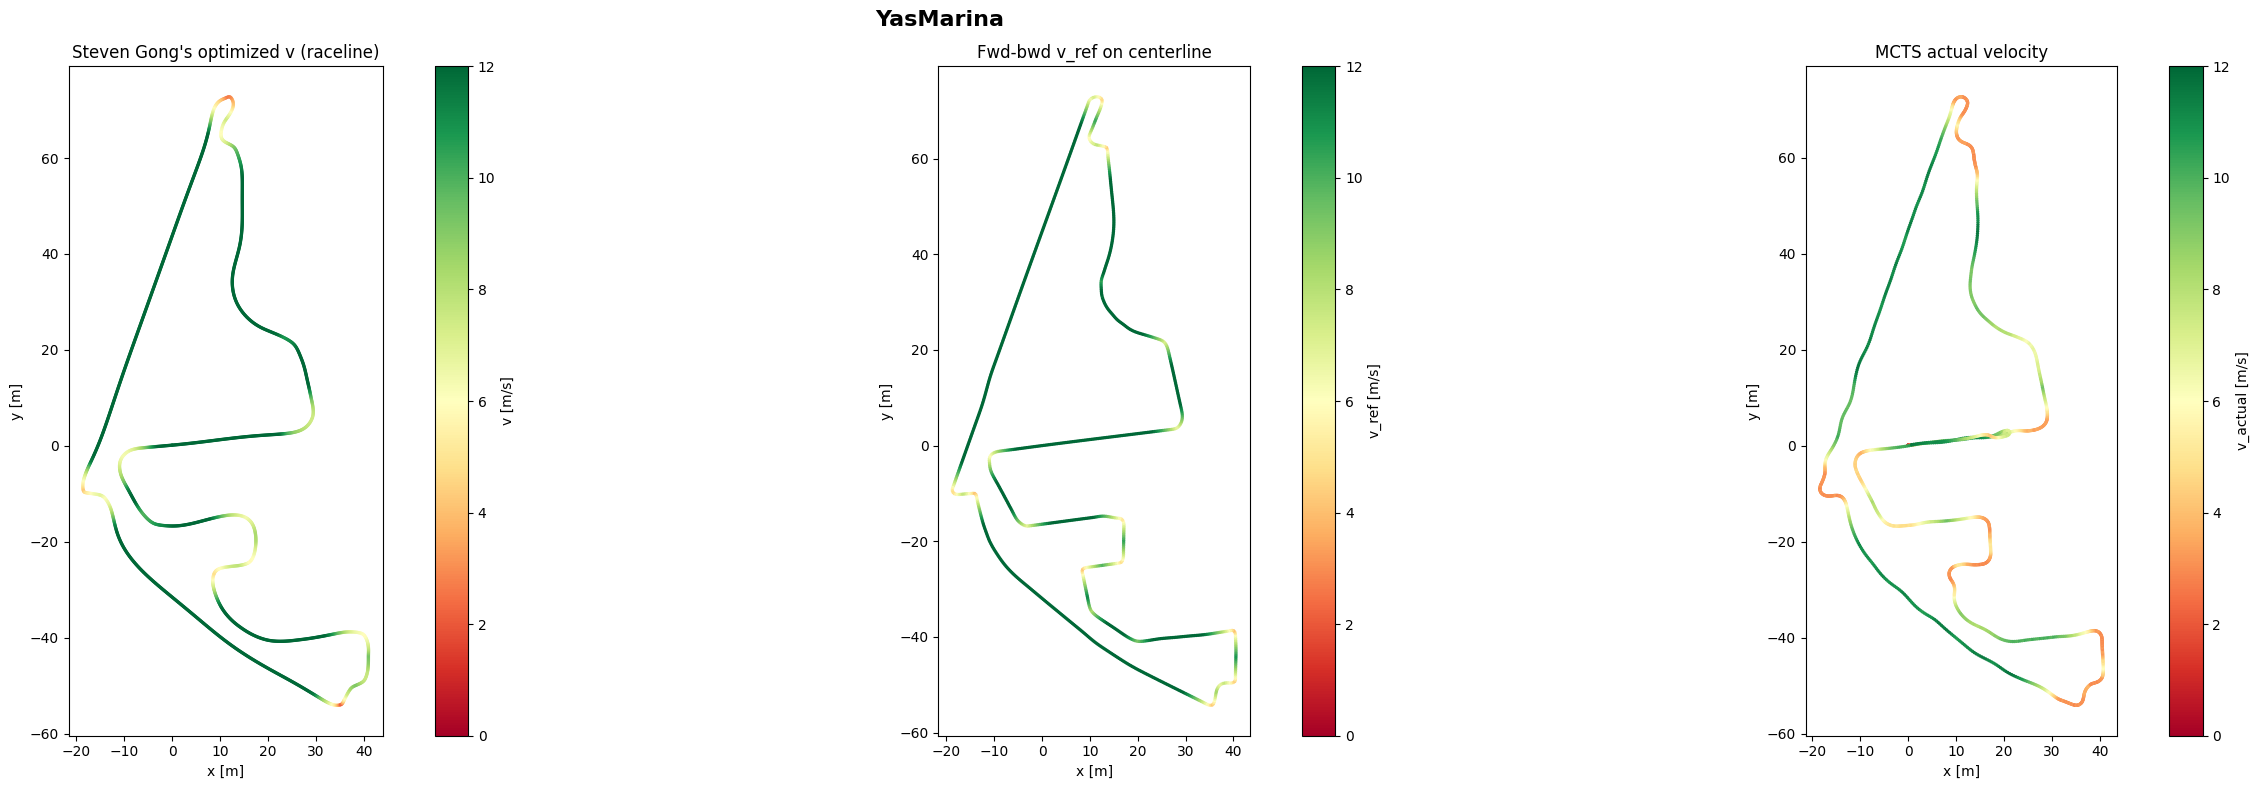

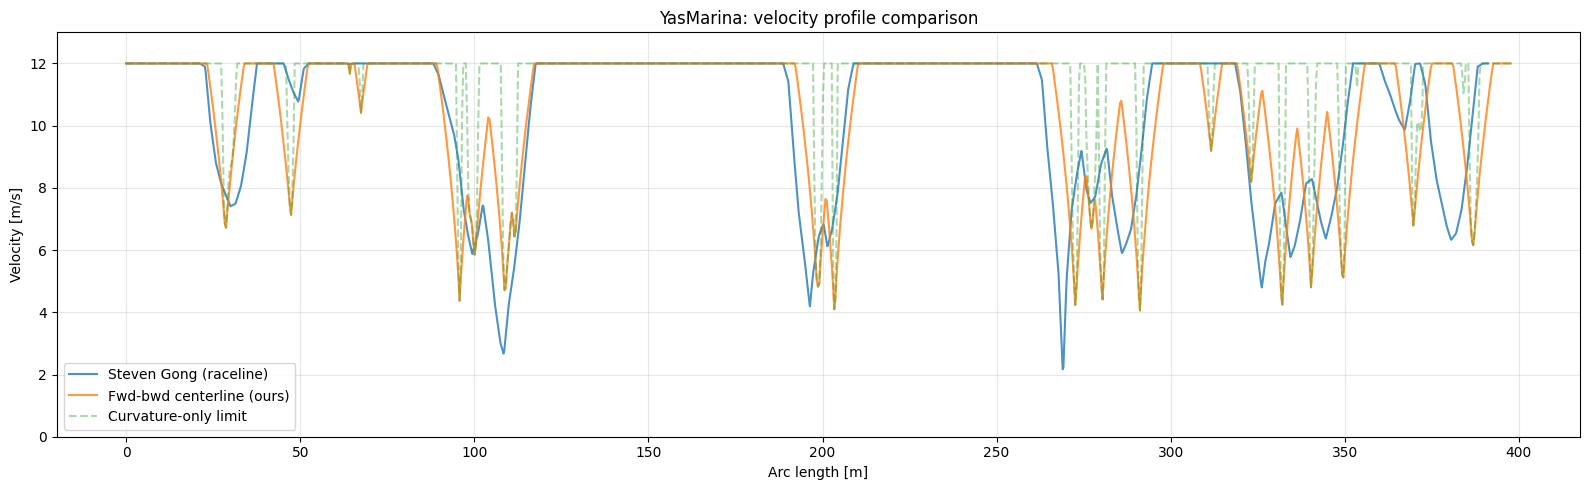

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(28, 8))
fig.suptitle('YasMarina', fontsize=16, fontweight='bold')

# Left: Steven Gong's optimized velocity (raceline)
sc0 = axes[0].scatter(ym_sg['x_m'], ym_sg['y_m'], c=ym_sg['vx_mps'], cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[0].set_title("Steven Gong's optimized v (raceline)")
axes[0].set_xlabel('x [m]')
axes[0].set_ylabel('y [m]')
axes[0].set_aspect('equal')
plt.colorbar(sc0, ax=axes[0], label='v [m/s]')

# Middle: our forward-backward on CENTERLINE
sc1 = axes[1].scatter(ym_cl_x, ym_cl_y, c=v_optimal_ym, cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[1].set_title('Fwd-bwd v_ref on centerline')
axes[1].set_xlabel('x [m]')
axes[1].set_ylabel('y [m]')
axes[1].set_aspect('equal')
plt.colorbar(sc1, ax=axes[1], label='v_ref [m/s]')

# Right: MCTS actual velocity
sc2 = axes[2].scatter(ym_x_mcts, ym_y_mcts, c=ym_v_actual, cmap='RdYlGn', s=2, vmin=0, vmax=12)
axes[2].set_title('MCTS actual velocity')
axes[2].set_xlabel('x [m]')
axes[2].set_ylabel('y [m]')
axes[2].set_aspect('equal')
plt.colorbar(sc2, ax=axes[2], label='v_actual [m/s]')

plt.tight_layout()
plt.show()

# Velocity vs arc length
fig2, ax2 = plt.subplots(figsize=(16, 5))
ax2.plot(ym_sg['s_m'], ym_sg['vx_mps'], label="Steven Gong (raceline)", alpha=0.8)
ax2.plot(ym_cl_s, v_optimal_ym, label="Fwd-bwd centerline (ours)", alpha=0.8)
ax2.plot(ym_cl_s, v_limit_ym, label="Curvature-only limit", alpha=0.4, linestyle='--')
ax2.set_xlabel('Arc length [m]')
ax2.set_ylabel('Velocity [m/s]')
ax2.set_title('YasMarina: velocity profile comparison')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 13)
plt.tight_layout()
plt.show()